# Мета роботи

Ознайомитися з базовим workflow задачі класифікації: від вибору та аналізу даних до навчання, налаштування, порівняння та оцінювання моделей машинного навчання з використанням бібліотеки **Scikit-learn**.

---

# Завдання

Оберіть датасет для задачі класифікації та виконайте наступні кроки:

## 1. Завантаження та первинний аналіз даних

- Завантажити датасет.
- Вивести назви колонок та розмір датасета.
- Визначити ознаки (**features**) та цільову змінну (**target**).
- Перевірити типи даних та розподіл об'єктів за класами.

## 2. Попередня обробка даних

- Перевірити наявність пропущених значень.
- За необхідності заповнити або видалити пропуски.
- Якщо датасет містить категоріальні ознаки — виконати їх кодування.
- Коротко пояснити прийняті рішення щодо попередньої обробки даних.

## 3. Візуалізація та дослідження даних (EDA)

Провести базовий **Exploratory Data Analysis**:

- Побудувати `heatmap` кореляцій числових ознак.
- Побудувати гістограми розподілу ознак.
- Побудувати `boxplot`-и ознак відносно цільової змінної.
- Коротко прокоментувати отримані візуалізації.

## 4. Підготовка даних до навчання

- Розділити дані на **training** та **test** вибірки.
- Виконати масштабування/нормалізацію ознак для алгоритмів, для яких це необхідно.

## 5. Навчання моделей

Навчити наступні класифікатори:

| № | Модель |
|---|--------|
| 1 | k-Nearest Neighbors (kNN) |
| 2 | Decision Tree |
| 3 | Support Vector Machine (SVM) |
| 4 | Random Forest |
| 5 | AdaBoost |

## 6. Підбір гіперпараметрів

- Для **kNN** підібрати оптимальне значення `n_neighbors`.
- Для **SVM** за допомогою `GridSearchCV` підібрати оптимальні значення `C` та `gamma`.
- За бажанням можна дослідити вплив гіперпараметрів і для інших моделей.

## 7. Порівняння та оцінювання моделей

- Порівняти результати всіх навчених класифікаторів та визначити найкращу модель для обраного датасета.

Для моделей вивести та проаналізувати:

- `sklearn.metrics.classification_report`
- `sklearn.metrics.confusion_matrix`

Зробити короткий висновок: **яка модель показала найкращий результат і чому**, на вашу думку, вона краще підходить для обраних даних.

### Імпортуємо модулі

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

### 1. Завантаження та первинний аналіз даних 

In [12]:
data = pd.read_csv("/Users/yurab/Desktop/Python for university/Intelligent-analysis/Lab 1 (Basic classification algorithms)/gta6_fan_expectations_2026.csv")
data

,respondent_id,age,gender,region,primary_platform,favorite_previous_gta,years_following_gta6,primary_info_source,trailer1_times_watched,most_anticipated_feature,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,hype_change_vs_6mo_ago,overall_sentiment
0,R100000,30,Male,Europe,Undecided,GTA San Andreas,5,Reddit,13,Better driving physics,10,5,No,96.0,19,Yes,No,Yes,Same,Very Positive
1,R100001,29,Male,Europe,PC,GTA San Andreas,4,X/Twitter,15,Dual protagonists (Jason & Lucia),10,3,Yes,70.0,10,No,No,No,Same,Very Positive
2,R100002,28,Female,Europe,Xbox Series X/S,GTA V,6,YouTube,9,Story & narrative depth,7,5,Maybe,81.0,6,No,No,Yes,Increased,Positive
3,R100003,30,Male,Europe,Xbox Series X/S,GTA Vice City,8,Gaming news sites,6,Online/multiplayer mode,8,4,Yes,80.0,11,Yes,No,Yes,Increased,Very Positive
4,R100004,40,Male,Europe,PlayStation 5,GTA V,10,TikTok,8,Realistic economy & businesses,8,4,No,69.0,25,Yes,Yes,No,Same,Very Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,R105995,15,Male,Asia-Pacific,PlayStation 5,GTA San Andreas,9,Official Rockstar trailer,8,Open-world Vice City map,10,3,Yes,94.0,12,Yes,No,Yes,Same,Very Positive
5996,R105996,22,Male,North America,PC,GTA V,2,Gaming news sites,11,Open-world Vice City map,10,4,Yes,108.0,25,Yes,No,Yes,Increased,Very Positive
5997,R105997,36,Male,North America,PlayStation 5,GTA IV,1,TikTok,4,Deeper character customization,8,3,Yes,68.0,17,Yes,No,Yes,Increased,Very Positive
5998,R105998,13,Non-binary,Europe,PlayStation 5,GTA Vice City,1,X/Twitter,5,Open-world Vice City map,7,2,Yes,43.0,12,Yes,No,Yes,Same,Positive


In [13]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 20 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   respondent_id                      6000 non-null   object 
 1   age                                6000 non-null   int64  
 2   gender                             5940 non-null   object 
 3   region                             6000 non-null   object 
 4   primary_platform                   6000 non-null   object 
 5   favorite_previous_gta              6000 non-null   object 
 6   years_following_gta6               6000 non-null   int64  
 7   primary_info_source                6000 non-null   object 
 8   trailer1_times_watched             6000 non-null   int64  
 9   most_anticipated_feature           6000 non-null   object 
 10  hype_score_1to10                   6000 non-null   int64  
 11  confidence_rockstar_delivers_1to5  6000 non-null   int64

Як можна побачити за результатами отриманих даних по даному датасету маємо, що "нульові" значення - відсутні, окрім колонок `gender` та `willingness_to_pay_usd`.

Виводимо унікальні значення колонки `gender` та к-ть конкретних даних 

In [14]:
data['gender'].unique()

array(['Male', 'Female', 'Prefer not to say', 'Non-binary', nan],
      dtype=object)

In [15]:
data['gender'].value_counts()

gender
Male                 4226
Female               1300
Non-binary            243
Prefer not to say     171
Name: count, dtype: int64

Прибираємо очевидно зайву колонку `respondent_id`, що очевидно не несе жодної важливої інформації для нашої майбутньої моделі

In [16]:
data.drop(labels='respondent_id', axis=1, inplace=True)
data

,age,gender,region,primary_platform,favorite_previous_gta,years_following_gta6,primary_info_source,trailer1_times_watched,most_anticipated_feature,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,hype_change_vs_6mo_ago,overall_sentiment
0,30,Male,Europe,Undecided,GTA San Andreas,5,Reddit,13,Better driving physics,10,5,No,96.0,19,Yes,No,Yes,Same,Very Positive
1,29,Male,Europe,PC,GTA San Andreas,4,X/Twitter,15,Dual protagonists (Jason & Lucia),10,3,Yes,70.0,10,No,No,No,Same,Very Positive
2,28,Female,Europe,Xbox Series X/S,GTA V,6,YouTube,9,Story & narrative depth,7,5,Maybe,81.0,6,No,No,Yes,Increased,Positive
3,30,Male,Europe,Xbox Series X/S,GTA Vice City,8,Gaming news sites,6,Online/multiplayer mode,8,4,Yes,80.0,11,Yes,No,Yes,Increased,Very Positive
4,40,Male,Europe,PlayStation 5,GTA V,10,TikTok,8,Realistic economy & businesses,8,4,No,69.0,25,Yes,Yes,No,Same,Very Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,Male,Asia-Pacific,PlayStation 5,GTA San Andreas,9,Official Rockstar trailer,8,Open-world Vice City map,10,3,Yes,94.0,12,Yes,No,Yes,Same,Very Positive
5996,22,Male,North America,PC,GTA V,2,Gaming news sites,11,Open-world Vice City map,10,4,Yes,108.0,25,Yes,No,Yes,Increased,Very Positive
5997,36,Male,North America,PlayStation 5,GTA IV,1,TikTok,4,Deeper character customization,8,3,Yes,68.0,17,Yes,No,Yes,Increased,Very Positive
5998,13,Non-binary,Europe,PlayStation 5,GTA Vice City,1,X/Twitter,5,Open-world Vice City map,7,2,Yes,43.0,12,Yes,No,Yes,Same,Positive


In [17]:
data.isnull().sum()

age                                    0
gender                                60
region                                 0
primary_platform                       0
favorite_previous_gta                  0
years_following_gta6                   0
primary_info_source                    0
trailer1_times_watched                 0
most_anticipated_feature               0
hype_score_1to10                       0
confidence_rockstar_delivers_1to5      0
preorder_intent                        0
willingness_to_pay_usd               120
expected_firstweek_hours               0
expects_release_delay                  0
worried_about_price                    0
follows_rockstar_socials               0
hype_change_vs_6mo_ago                 0
overall_sentiment                      0
dtype: int64

Виводимо унікальні значення для колонки `willingness_to_pay_usd` і переконуємось в присутності "відсутніх значень"

In [18]:
data['willingness_to_pay_usd'].unique()

array([ 96.,  70.,  81.,  80.,  69.,  90.,  59.,  87.,  71.,  39.,  66.,
        94.,  86.,  95.,  41.,  46.,  72.,  77.,  62.,  79.,  92.,  64.,
        73.,  88.,  44.,  48.,  84.,  63.,  67.,  55.,  61.,  51.,  74.,
        78.,  58.,  91.,  68.,  85.,  56.,  54.,  50.,  47.,  83.,  45.,
        89.,  65.,  53., 103.,  17.,  22.,  60.,  nan,  82.,  75., 104.,
        57.,  52.,  28.,  97.,  42.,  36.,  98.,  76., 112.,  49.,  93.,
        43., 102.,  35.,  38., 106., 100.,  99.,  40.,  12.,  25., 108.,
        23.,  31.,  32.,  30.,  26.,  33., 105.,  37., 101., 109.,  34.,
       110., 113., 111., 107.,  20., 115., 114.,  27.,  29., 118., 119.,
        18., 120.,   6., 116.,  24.])

Створюємо розподіл значень для подальшого розуміння розподілу кількості значення та їхнього відсоткового внеску

In [19]:
dictionary = {}
for i in data.columns:
    counts = data[i].value_counts()
    percent = data[i].value_counts(normalize=True).round(3) * 100

    stats = pd.DataFrame({
        'Count': counts,
        'Percentage (%)': percent
    })
    
    dictionary[i] = stats

dictionary

{'age':      Count  Percentage (%)
 age                       
 13     345             5.8
 26     317             5.3
 25     312             5.2
 29     307             5.1
 23     300             5.0
 24     295             4.9
 27     287             4.8
 28     284             4.7
 22     255             4.2
 20     254             4.2
 30     245             4.1
 21     221             3.7
 19     209             3.5
 32     203             3.4
 31     199             3.3
 33     198             3.3
 34     182             3.0
 17     178             3.0
 18     171             2.8
 35     165             2.8
 36     146             2.4
 16     135             2.2
 15     111             1.8
 14     108             1.8
 37     100             1.7
 39      99             1.6
 38      95             1.6
 40      71             1.2
 41      59             1.0
 43      35             0.6
 42      33             0.6
 44      20             0.3
 45      16             0.3
 46      14  

### 2. Обробка даних

Оскільки відсотковий внесок кожного типу у гендерну колонку не чоловіка або жінки становить <= 5 %, то було прийнете відповідне рішення обʼєднати такі значення у єдиний "Не бінарний" тип

In [20]:
data['gender'] = data['gender'].where(data['gender'].isin(['Male', 'Female']), 'Non-binary')
data['gender'].unique()

array(['Male', 'Female', 'Non-binary'], dtype=object)

Оскільки відсотковий внесок нан у колонку `willingness_to_pay_usd` <= 5 %, то було прийнято рішення обрати середнє значення як самий простий спосіб заповнення значень

In [21]:
mean = data['willingness_to_pay_usd'].mean()
int(mean)

71

In [22]:
data['willingness_to_pay_usd'] = data['willingness_to_pay_usd'].fillna(int(mean))
data['willingness_to_pay_usd'].unique()

array([ 96.,  70.,  81.,  80.,  69.,  90.,  59.,  87.,  71.,  39.,  66.,
        94.,  86.,  95.,  41.,  46.,  72.,  77.,  62.,  79.,  92.,  64.,
        73.,  88.,  44.,  48.,  84.,  63.,  67.,  55.,  61.,  51.,  74.,
        78.,  58.,  91.,  68.,  85.,  56.,  54.,  50.,  47.,  83.,  45.,
        89.,  65.,  53., 103.,  17.,  22.,  60.,  82.,  75., 104.,  57.,
        52.,  28.,  97.,  42.,  36.,  98.,  76., 112.,  49.,  93.,  43.,
       102.,  35.,  38., 106., 100.,  99.,  40.,  12.,  25., 108.,  23.,
        31.,  32.,  30.,  26.,  33., 105.,  37., 101., 109.,  34., 110.,
       113., 111., 107.,  20., 115., 114.,  27.,  29., 118., 119.,  18.,
       120.,   6., 116.,  24.])

Перевіряємо отримані значення

In [23]:
data

,age,gender,region,primary_platform,favorite_previous_gta,years_following_gta6,primary_info_source,trailer1_times_watched,most_anticipated_feature,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,hype_change_vs_6mo_ago,overall_sentiment
0,30,Male,Europe,Undecided,GTA San Andreas,5,Reddit,13,Better driving physics,10,5,No,96.0,19,Yes,No,Yes,Same,Very Positive
1,29,Male,Europe,PC,GTA San Andreas,4,X/Twitter,15,Dual protagonists (Jason & Lucia),10,3,Yes,70.0,10,No,No,No,Same,Very Positive
2,28,Female,Europe,Xbox Series X/S,GTA V,6,YouTube,9,Story & narrative depth,7,5,Maybe,81.0,6,No,No,Yes,Increased,Positive
3,30,Male,Europe,Xbox Series X/S,GTA Vice City,8,Gaming news sites,6,Online/multiplayer mode,8,4,Yes,80.0,11,Yes,No,Yes,Increased,Very Positive
4,40,Male,Europe,PlayStation 5,GTA V,10,TikTok,8,Realistic economy & businesses,8,4,No,69.0,25,Yes,Yes,No,Same,Very Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,Male,Asia-Pacific,PlayStation 5,GTA San Andreas,9,Official Rockstar trailer,8,Open-world Vice City map,10,3,Yes,94.0,12,Yes,No,Yes,Same,Very Positive
5996,22,Male,North America,PC,GTA V,2,Gaming news sites,11,Open-world Vice City map,10,4,Yes,108.0,25,Yes,No,Yes,Increased,Very Positive
5997,36,Male,North America,PlayStation 5,GTA IV,1,TikTok,4,Deeper character customization,8,3,Yes,68.0,17,Yes,No,Yes,Increased,Very Positive
5998,13,Non-binary,Europe,PlayStation 5,GTA Vice City,1,X/Twitter,5,Open-world Vice City map,7,2,Yes,43.0,12,Yes,No,Yes,Same,Positive


Створюємо кодування "one_hot_encoding" для наступних 6 колонок

In [24]:
data = pd.get_dummies(data, columns=['gender', 'region', 'primary_platform', 'favorite_previous_gta', 'primary_info_source', 'most_anticipated_feature'], dtype=int)
data

,age,years_following_gta6,trailer1_times_watched,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,...,most_anticipated_feature_Better driving physics,most_anticipated_feature_Deeper character customization,most_anticipated_feature_Dual protagonists (Jason & Lucia),most_anticipated_feature_Graphics & ray tracing,most_anticipated_feature_Improved police/AI systems,most_anticipated_feature_Map size & exploration,most_anticipated_feature_Online/multiplayer mode,most_anticipated_feature_Open-world Vice City map,most_anticipated_feature_Realistic economy & businesses,most_anticipated_feature_Story & narrative depth
0,30,5,13,10,5,No,96.0,19,Yes,No,...,1,0,0,0,0,0,0,0,0,0
1,29,4,15,10,3,Yes,70.0,10,No,No,...,0,0,1,0,0,0,0,0,0,0
2,28,6,9,7,5,Maybe,81.0,6,No,No,...,0,0,0,0,0,0,0,0,0,1
3,30,8,6,8,4,Yes,80.0,11,Yes,No,...,0,0,0,0,0,0,1,0,0,0
4,40,10,8,8,4,No,69.0,25,Yes,Yes,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,9,8,10,3,Yes,94.0,12,Yes,No,...,0,0,0,0,0,0,0,1,0,0
5996,22,2,11,10,4,Yes,108.0,25,Yes,No,...,0,0,0,0,0,0,0,1,0,0
5997,36,1,4,8,3,Yes,68.0,17,Yes,No,...,0,1,0,0,0,0,0,0,0,0
5998,13,1,5,7,2,Yes,43.0,12,Yes,No,...,0,0,0,0,0,0,0,1,0,0


Створюємо кодування "label_encoding" для наступних 3 колонок 

In [25]:
preorder = {'No': 0, 'Maybe': 1, 'Yes': 2}
hype_change = {'Decreased': 0, 'Same': 1, 'Increased': 2}
sentiment = {'Neutral/Cautious': 0, 'Positive': 1, 'Very Positive': 2}

data['preorder_intent'] = data['preorder_intent'].map(preorder)
data['hype_change_vs_6mo_ago'] = data['hype_change_vs_6mo_ago'].map(hype_change)
data['overall_sentiment'] = data['overall_sentiment'].map(sentiment)

data

,age,years_following_gta6,trailer1_times_watched,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,...,most_anticipated_feature_Better driving physics,most_anticipated_feature_Deeper character customization,most_anticipated_feature_Dual protagonists (Jason & Lucia),most_anticipated_feature_Graphics & ray tracing,most_anticipated_feature_Improved police/AI systems,most_anticipated_feature_Map size & exploration,most_anticipated_feature_Online/multiplayer mode,most_anticipated_feature_Open-world Vice City map,most_anticipated_feature_Realistic economy & businesses,most_anticipated_feature_Story & narrative depth
0,30,5,13,10,5,0,96.0,19,Yes,No,...,1,0,0,0,0,0,0,0,0,0
1,29,4,15,10,3,2,70.0,10,No,No,...,0,0,1,0,0,0,0,0,0,0
2,28,6,9,7,5,1,81.0,6,No,No,...,0,0,0,0,0,0,0,0,0,1
3,30,8,6,8,4,2,80.0,11,Yes,No,...,0,0,0,0,0,0,1,0,0,0
4,40,10,8,8,4,0,69.0,25,Yes,Yes,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,9,8,10,3,2,94.0,12,Yes,No,...,0,0,0,0,0,0,0,1,0,0
5996,22,2,11,10,4,2,108.0,25,Yes,No,...,0,0,0,0,0,0,0,1,0,0
5997,36,1,4,8,3,2,68.0,17,Yes,No,...,0,1,0,0,0,0,0,0,0,0
5998,13,1,5,7,2,2,43.0,12,Yes,No,...,0,0,0,0,0,0,0,1,0,0


Створюємо кодування "label_encoding" (або для конкретно цього випадку більш правильно "binary_encoding") для наступних 3 колонок 

In [26]:
array = ['expects_release_delay', 'worried_about_price', 'follows_rockstar_socials']
for i in array:
    for j in range(len(data[i])):
        if data.loc[j, i] == 'Yes':
            data.loc[j, i] = 1
        else:
            data.loc[j, i] = 0

data            

,age,years_following_gta6,trailer1_times_watched,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,...,most_anticipated_feature_Better driving physics,most_anticipated_feature_Deeper character customization,most_anticipated_feature_Dual protagonists (Jason & Lucia),most_anticipated_feature_Graphics & ray tracing,most_anticipated_feature_Improved police/AI systems,most_anticipated_feature_Map size & exploration,most_anticipated_feature_Online/multiplayer mode,most_anticipated_feature_Open-world Vice City map,most_anticipated_feature_Realistic economy & businesses,most_anticipated_feature_Story & narrative depth
0,30,5,13,10,5,0,96.0,19,1,0,...,1,0,0,0,0,0,0,0,0,0
1,29,4,15,10,3,2,70.0,10,0,0,...,0,0,1,0,0,0,0,0,0,0
2,28,6,9,7,5,1,81.0,6,0,0,...,0,0,0,0,0,0,0,0,0,1
3,30,8,6,8,4,2,80.0,11,1,0,...,0,0,0,0,0,0,1,0,0,0
4,40,10,8,8,4,0,69.0,25,1,1,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,9,8,10,3,2,94.0,12,1,0,...,0,0,0,0,0,0,0,1,0,0
5996,22,2,11,10,4,2,108.0,25,1,0,...,0,0,0,0,0,0,0,1,0,0
5997,36,1,4,8,3,2,68.0,17,1,0,...,0,1,0,0,0,0,0,0,0,0
5998,13,1,5,7,2,2,43.0,12,1,0,...,0,0,0,0,0,0,0,1,0,0


### 3. Візуалізація та дослідження даних

Виводимо числове представлення кореляції та приходимо до висновку, що дане представлення не є ефективним

In [19]:
data.corr()

,age,years_following_gta6,trailer1_times_watched,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,...,most_anticipated_feature_Better driving physics,most_anticipated_feature_Deeper character customization,most_anticipated_feature_Dual protagonists (Jason & Lucia),most_anticipated_feature_Graphics & ray tracing,most_anticipated_feature_Improved police/AI systems,most_anticipated_feature_Map size & exploration,most_anticipated_feature_Online/multiplayer mode,most_anticipated_feature_Open-world Vice City map,most_anticipated_feature_Realistic economy & businesses,most_anticipated_feature_Story & narrative depth
age,1.000000,0.029215,-0.043454,-0.084675,-0.005165,-0.030464,-0.046366,-0.000725,-0.004268,-0.002637,...,0.005537,-0.024369,-0.025948,-0.005948,-0.010331,0.013943,0.026820,0.009160,0.003092,0.006330
years_following_gta6,0.029215,1.000000,0.029141,0.008826,0.014705,-0.002365,0.010605,0.009906,-0.001971,-0.006712,...,0.011092,-0.029697,0.005774,0.004675,-0.003715,0.014713,0.010211,-0.019946,0.006777,0.002268
trailer1_times_watched,-0.043454,0.029141,1.000000,0.590297,0.026749,0.241602,0.394801,0.100983,-0.003594,-0.116605,...,-0.016726,0.018706,0.006338,-0.017368,0.009453,0.005268,-0.003193,-0.018518,0.013667,0.003748
hype_score_1to10,-0.084675,0.008826,0.590297,1.000000,0.034418,0.392836,0.658778,0.164028,-0.006859,-0.195043,...,-0.019096,0.006287,0.023927,-0.007474,0.001623,0.003687,-0.010470,-0.003989,0.000299,-0.001498
confidence_rockstar_delivers_1to5,-0.005165,0.014705,0.026749,0.034418,1.000000,0.010512,0.035714,0.006350,-0.006650,-0.023488,...,0.006369,0.022475,-0.006766,0.005974,-0.010591,-0.007431,-0.023050,-0.015698,0.022071,0.015298
preorder_intent,-0.030464,-0.002365,0.241602,0.392836,0.010512,1.000000,0.268804,0.070794,-0.004899,-0.074986,...,-0.003536,-0.018310,-0.004280,0.018903,0.012949,0.016786,-0.002505,-0.014938,0.002375,-0.001143
willingness_to_pay_usd,-0.046366,0.010605,0.394801,0.658778,0.035714,0.268804,1.000000,0.119891,-0.013790,-0.281753,...,-0.018881,0.012606,0.002966,-0.000461,0.008431,0.020163,-0.012879,-0.015968,0.016144,-0.007381
expected_firstweek_hours,-0.000725,0.009906,0.100983,0.164028,0.006350,0.070794,0.119891,1.000000,-0.004540,-0.048169,...,-0.007544,0.013285,-0.003046,-0.000579,-0.015887,-0.004544,0.014724,0.003361,0.009760,-0.010538
expects_release_delay,-0.004268,-0.001971,-0.003594,-0.006859,-0.006650,-0.004899,-0.013790,-0.004540,1.000000,0.000001,...,0.006922,-0.003752,-0.006897,-0.003313,0.010166,-0.003558,0.010494,-0.015405,-0.005114,0.014629
worried_about_price,-0.002637,-0.006712,-0.116605,-0.195043,-0.023488,-0.074986,-0.281753,-0.048169,0.000001,1.000000,...,0.000294,0.004844,0.012872,-0.013481,-0.004753,-0.001314,0.012642,0.010491,0.001892,-0.028118


Обираємо 7 колонок для візуалізації кореляції ознак з майбутньою цільовою зміннною `preorder_intent`

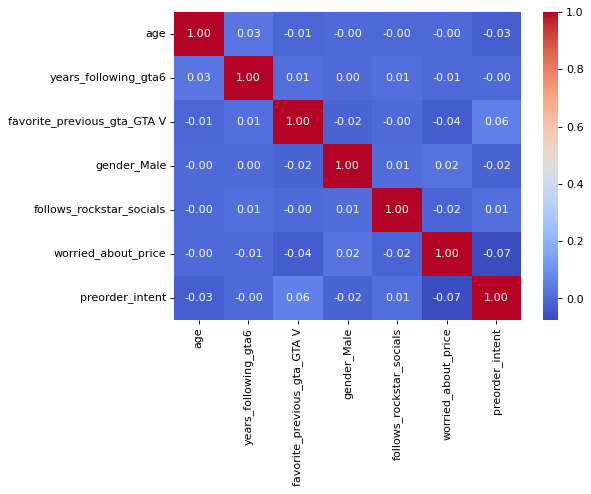

In [82]:
columns_for_shows = ['age', 'years_following_gta6', 'favorite_previous_gta_GTA V', 'gender_Male', 'follows_rockstar_socials', 'worried_about_price', 'preorder_intent']
corr = data[columns_for_shows].corr()
fig, ax = plt.subplots(figsize=(7,5), dpi=80)
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt='.2f')
plt.show()

Малюємо boxplot для 6 колонок відповідно, для демонастрації розподілу числових даних та їх розкид відповідно до середнього значення

In [21]:
colomns_for_shows = ['age', 'years_following_gta6', 'favorite_previous_gta_GTA V', 'gender_Male', 'follows_rockstar_socials', 'worried_about_price']

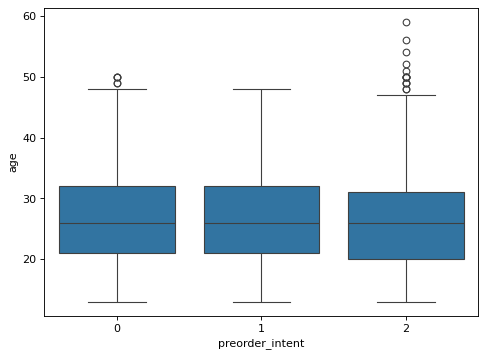

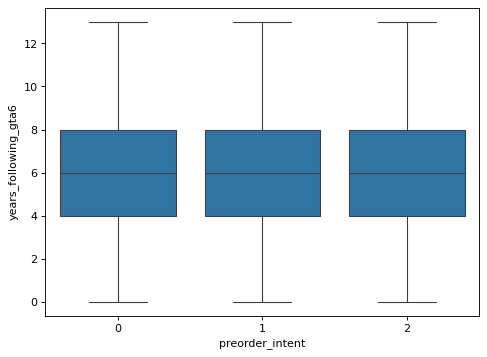

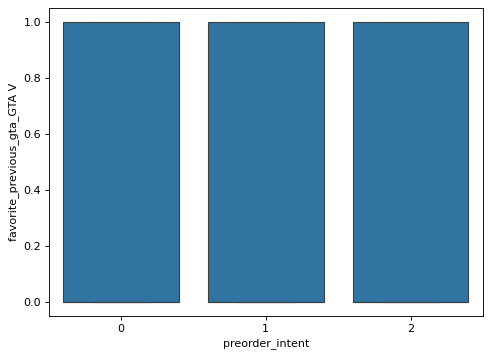

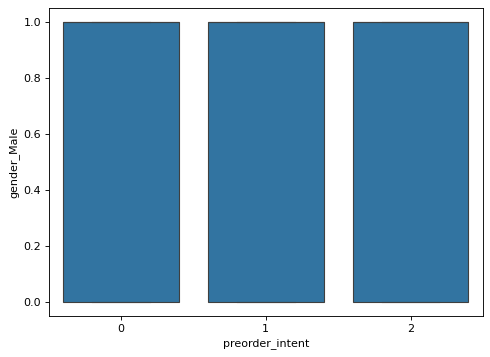

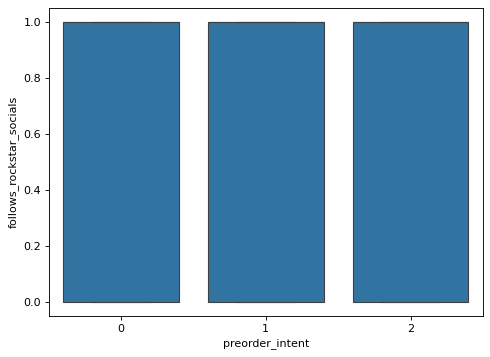

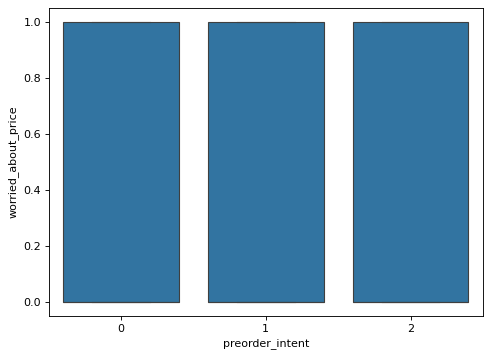

In [83]:
for i in range(len(colomns_for_shows)):
    fig = plt.figure(figsize=(7, 5), dpi=80)
    ax = sns.boxplot(x='preorder_intent', y=colomns_for_shows[i], data=data)

Створюємо відповідні гістограми для обраних колонок.

Як результат, то маємо: лог-нормальний розподіл, нормальний розподіл та бімодальний розподіл

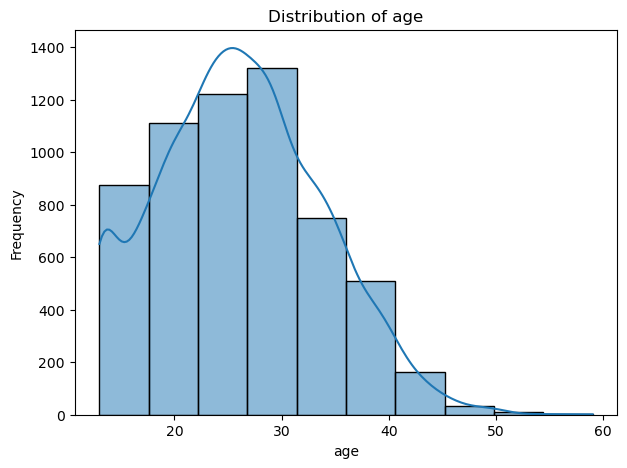

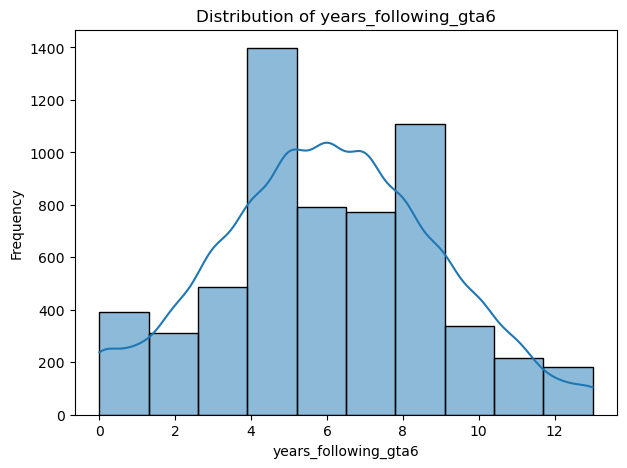

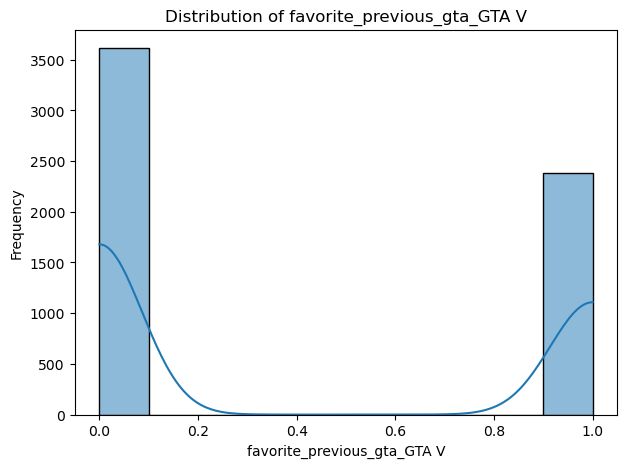

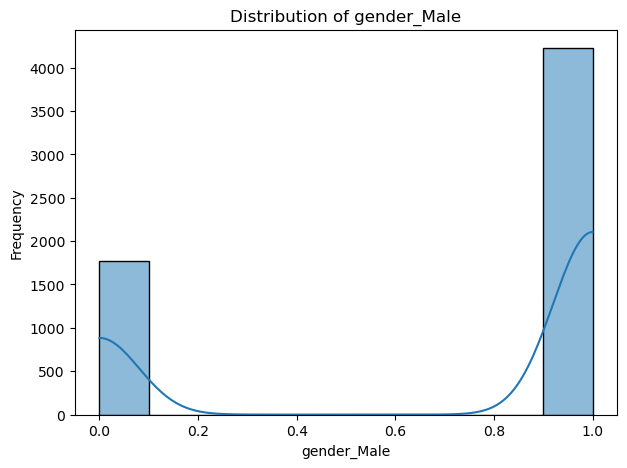

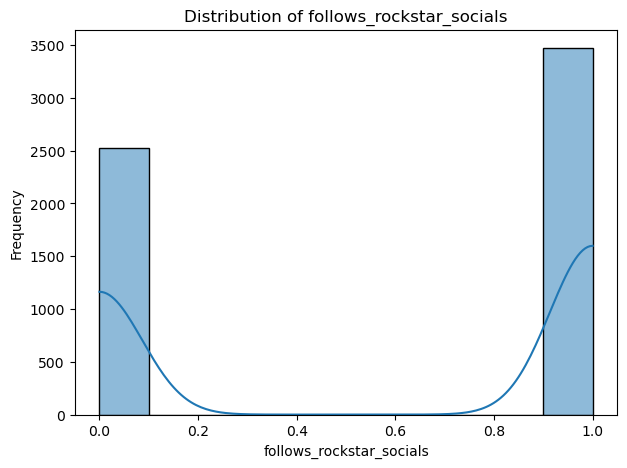

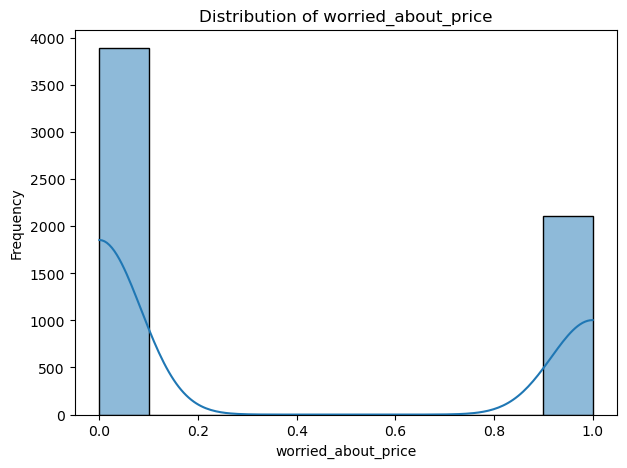

In [80]:
for i in colomns_for_shows:
    plt.figure(figsize=(7, 5))
    sns.histplot(data=data, x=i, bins=10, kde=True)
    plt.title(f'Distribution of {i}')
    plt.xlabel(i)
    plt.ylabel('Frequency')
    plt.show()

Будуємо матрицю графиків за допомогою інструменту пеірплот для демонстрації взаїмозалежності між парами ознак та розподілу кожної ознаки окремо

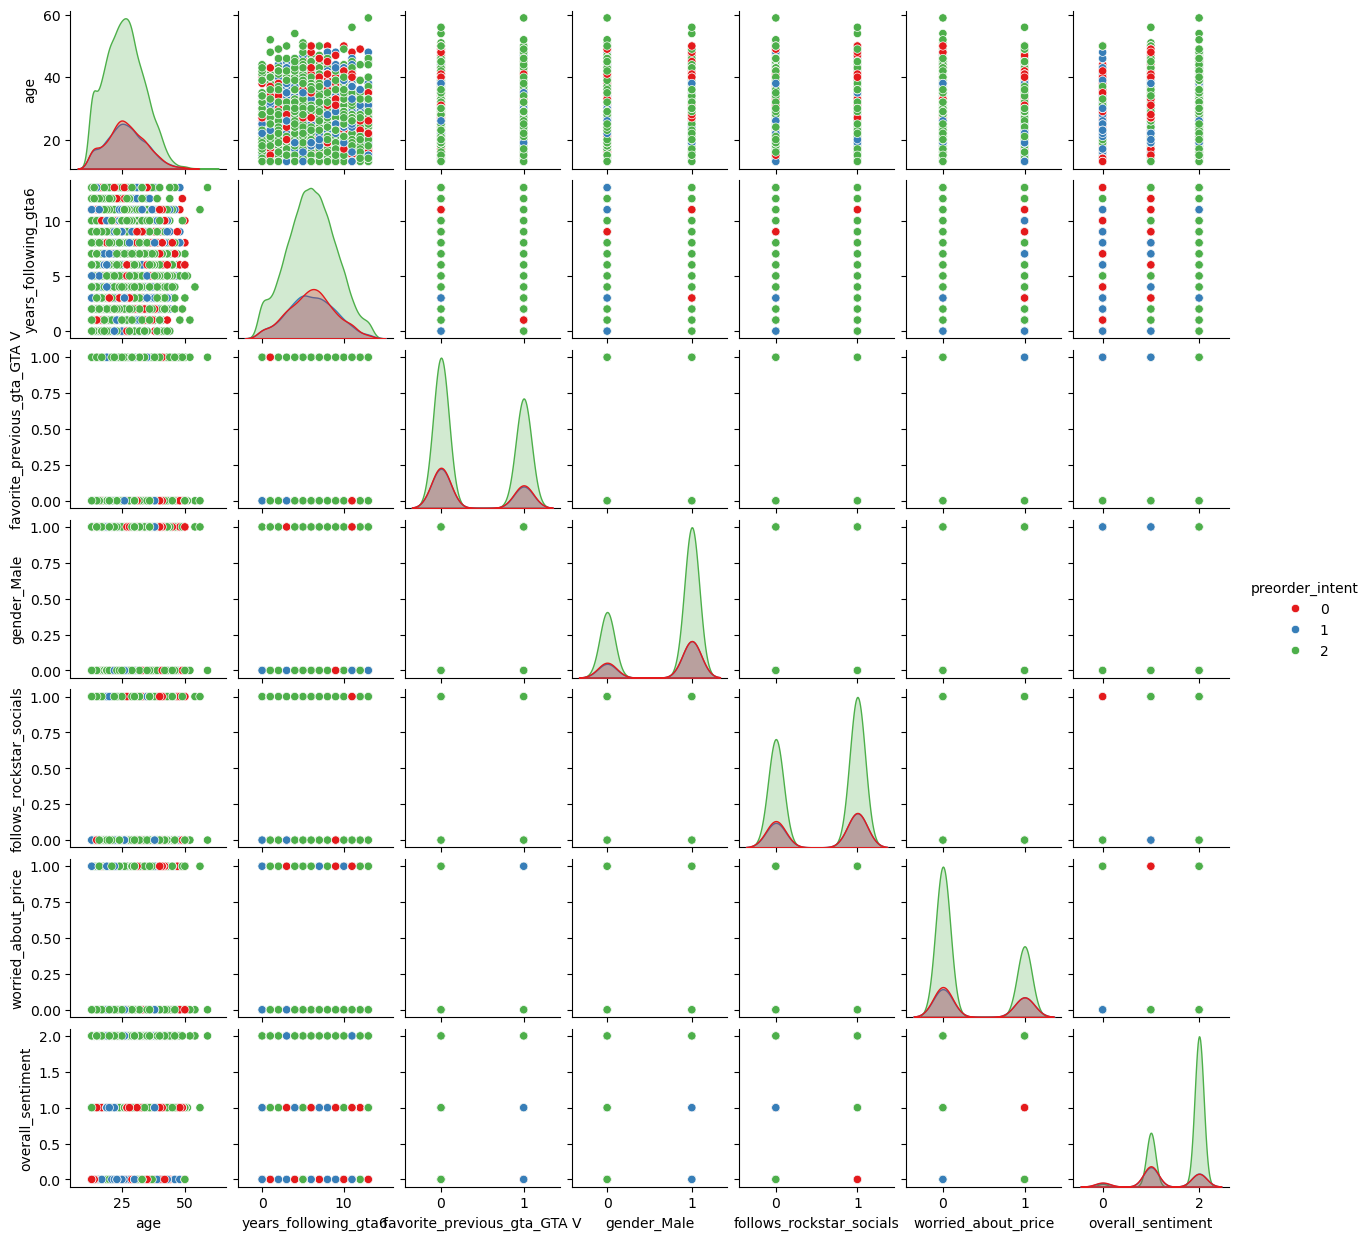

In [81]:
sns.pairplot(data, vars=columns_for_shows, hue='preorder_intent', palette='Set1', height=1.8)
plt.show()

Виводимо назви усіх колонок

In [24]:
data.columns

Index(['age', 'years_following_gta6', 'trailer1_times_watched',
       'hype_score_1to10', 'confidence_rockstar_delivers_1to5',
       'preorder_intent', 'willingness_to_pay_usd', 'expected_firstweek_hours',
       'expects_release_delay', 'worried_about_price',
       'follows_rockstar_socials', 'hype_change_vs_6mo_ago',
       'overall_sentiment', 'gender_Female', 'gender_Male',
       'gender_Non-binary', 'region_Africa', 'region_Asia-Pacific',
       'region_Europe', 'region_Latin America', 'region_Middle East',
       'region_North America', 'primary_platform_PC',
       'primary_platform_PlayStation 5', 'primary_platform_PlayStation 5 Pro',
       'primary_platform_Undecided', 'primary_platform_Xbox Series X/S',
       'favorite_previous_gta_GTA III', 'favorite_previous_gta_GTA IV',
       'favorite_previous_gta_GTA San Andreas', 'favorite_previous_gta_GTA V',
       'favorite_previous_gta_GTA Vice City',
       'favorite_previous_gta_Never played GTA',
       'favorite_previous_

### 4. Підготовка даних до навчання

Обираємо змінні `Х` по яким будемо передбачувати. Фактично прибираємо лише колонку `preorder_intent`

In [27]:
X = data.drop('preorder_intent', axis=1)
X

,age,years_following_gta6,trailer1_times_watched,hype_score_1to10,confidence_rockstar_delivers_1to5,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,...,most_anticipated_feature_Better driving physics,most_anticipated_feature_Deeper character customization,most_anticipated_feature_Dual protagonists (Jason & Lucia),most_anticipated_feature_Graphics & ray tracing,most_anticipated_feature_Improved police/AI systems,most_anticipated_feature_Map size & exploration,most_anticipated_feature_Online/multiplayer mode,most_anticipated_feature_Open-world Vice City map,most_anticipated_feature_Realistic economy & businesses,most_anticipated_feature_Story & narrative depth
0,30,5,13,10,5,96.0,19,1,0,1,...,1,0,0,0,0,0,0,0,0,0
1,29,4,15,10,3,70.0,10,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,28,6,9,7,5,81.0,6,0,0,1,...,0,0,0,0,0,0,0,0,0,1
3,30,8,6,8,4,80.0,11,1,0,1,...,0,0,0,0,0,0,1,0,0,0
4,40,10,8,8,4,69.0,25,1,1,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,9,8,10,3,94.0,12,1,0,1,...,0,0,0,0,0,0,0,1,0,0
5996,22,2,11,10,4,108.0,25,1,0,1,...,0,0,0,0,0,0,0,1,0,0
5997,36,1,4,8,3,68.0,17,1,0,1,...,0,1,0,0,0,0,0,0,0,0
5998,13,1,5,7,2,43.0,12,1,0,1,...,0,0,0,0,0,0,0,1,0,0


Обираємо цільову змінну `Y` - колонка `preorder_intent`

In [28]:
Y = data[['preorder_intent']]
Y

,preorder_intent
0,0
1,2
2,1
3,2
4,0
...,...
5995,2
5996,2
5997,2
5998,2


Розділяємо наші Х та У на тренувальну та тестувальні вибірки відповідно. Однак, оскільки наші класи не збалансовані, то розділяємо зі збереженням відповідної пропорції

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, train_size=0.8, random_state=42, stratify=Y)
# stratify for keeping the same class proportion. We use it when dealing with imbalanced class

Розмірність отриманих змінних

In [30]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(4800, 51)
(1200, 51)
(4800, 1)
(1200, 1)


### 5. Навчання моделей

#### Decision Tree

Критерій:

Доля спостережень класа \(k\) в узле \(m\).

$$p_{mk} = \frac{1}{n_m} \sum_{y \in Q_m} I(y = k)$$

**Gini**

$$H(Q_m) = \sum_{k} p_{mk} (1 - p_{mk})$$

**Entropy**

$$H(Q_m) = -\sum_{k} p_{mk} \log(p_{mk})$$

Максимальна глубина - встановлює максимальне можливе заглиблення для дерева.

Ваги: або дефолтні None, або баланс (n_samples / (n_classes * np.bincount(y)))

Мінімум для розділення встановлює межу при якій дерево може ділитись надалі, к-ть семплів, що має необхідно бути для заглиблення дерева. (Тісно повʼязане з мінімільною кількістю листів, має бути в 2-3 рази більшою, початкова к-ть семплів - 6000).

Мінімум листів встановлює мінімально необхідну к-ть семплів, що можуть бути у вузлі на фінальному рівні. 

In [31]:
model_DT = DecisionTreeClassifier(criterion='entropy', max_depth=5, class_weight='balanced', min_samples_leaf=7, min_samples_split=14, random_state=42)

Тренуємо модель

In [32]:
model_DT.fit(X_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,5
,min_samples_split,14
,min_samples_leaf,7
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


Предиктимо модель

In [33]:
y_pred = model_DT.predict(X_test)

Точність, яка доля обʼєктів, яким модель присвоїла певний клас дійсно належить цьому обʼєкту:

$$Precision = TP / (TP + FP)$$

Повнота, яка доля обʼєктів із всіх реальних представників цього класа модель змогла правильно знайти та визначити (етака метрика відчутності):

$$Recall = TP / (TP + FN)$$

Баланс, F-метрика:

$$F1 = 2 * (Precision * Recall) / (Precision + Recall)$$

Точність на тестовій вибірці:

$$Accuracy = Всі~правильні~відповіді / к-ть~елементів$$

Макро-середнє:

$$Macro_{F1} = Сума~всіх~F1 / к-ть~класів$$

Взважене середнє:

$$Weight_{F1} = Сума~всіх (F1 * відповідний~support) / к-ть~елементів$$

In [34]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.31      0.25      0.28       226
           1       0.26      0.39      0.31       219
           2       0.78      0.72      0.75       755

    accuracy                           0.57      1200
   macro avg       0.45      0.45      0.45      1200
weighted avg       0.60      0.57      0.58      1200



Таблиця відображає відповідність між реальними класами та прогнозами моделі для трикласової класифікації. Рядки відповідають реальним класам, а стовпці — передбаченим моделлю. 

|                     | Передбачено Клас 0 | Передбачено Клас 1 | Передбачено Клас 2 |
| :------------------ | :----------------: | :----------------: | :----------------: |
| **Реальний Клас 0** |    **Правильно**   |     **Помилка**    |     **Помилка**    |
| **Реальний Клас 1** |     **Помилка**    |    **Правильно**   |     **Помилка**    |
| **Реальний Клас 2** |     **Помилка**    |     **Помилка**    |    **Правильно**   |


In [35]:
print(confusion_matrix(y_test, y_pred))

[[ 57  96  73]
 [ 55  85  79]
 [ 71 144 540]]


Демонстрація впливу кожної з ознак на фінальний результат

In [36]:
importances = pd.Series(model_DT.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print(importances)

hype_score_1to10                                              7.428959e-01
willingness_to_pay_usd                                        4.307887e-02
age                                                           4.165437e-02
primary_platform_Undecided                                    3.662531e-02
expected_firstweek_hours                                      3.126103e-02
trailer1_times_watched                                        3.073354e-02
years_following_gta6                                          1.289713e-02
most_anticipated_feature_Online/multiplayer mode              1.266121e-02
expects_release_delay                                         1.257012e-02
primary_platform_PC                                           1.230872e-02
primary_info_source_X/Twitter                                 1.190466e-02
primary_platform_Xbox Series X/S                              7.287380e-03
confidence_rockstar_delivers_1to5                             4.121700e-03
favorite_previous_gta_GTA

#### Random Forest

К-ть прогонів: задає кількість незалежних базових дерев рішень у ансамблі, на основі голосування більшості (majority voting) яких приймається фінальне рішення моделі.

Критерій:

Доля спостережень класа \(k\) в узле \(m\).

$$p_{mk} = \frac{1}{n_m} \sum_{y \in Q_m} I(y = k)$$

**Gini**

$$H(Q_m) = \sum_{k} p_{mk} (1 - p_{mk})$$

**Entropy**

$$H(Q_m) = -\sum_{k} p_{mk} \log(p_{mk})$$

Максимальна глубина - встановлює максимальне можливе заглиблення для дерева.

Ваги: або дефолтні None, або баланс (n_samples / (n_classes * np.bincount(y)))

In [34]:
model_RF = RandomForestClassifier(n_estimators=500, criterion='entropy', class_weight='balanced', random_state=42)

Навчання моделі

In [35]:
model_RF.fit(X_train, y_train.values.reshape(-1))

,n_estimators,500
,criterion,'entropy'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Створення предикту

In [36]:
y_pred = model_RF.predict(X_test)

Точність, яка доля обʼєктів, яким модель присвоїла певний клас дійсно належить цьому обʼєкту:

$$Precision = TP / (TP + FP)$$

Повнота, яка доля обʼєктів із всіх реальних представників цього класа модель змогла правильно знайти та визначити (етака метрика відчутності):

$$Recall = TP / (TP + FN)$$

Баланс, F-метрика:

$$F1 = 2 * (Precision * Recall) / (Precision + Recall)$$

Точність на тестовій вибірці:

$$Accuracy = Всі~правильні~відповіді / к-ть~елементів$$

Макро-середнє:

$$Macro_{F1} = Сума~всіх~F1 / к-ть~класів$$

Взважене середнє:

$$Weight_{F1} = Сума~всіх (F1 * відповідний~support) / к-ть~елементів$$

In [37]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.38      0.11      0.17       226
           1       0.31      0.08      0.12       219
           2       0.67      0.95      0.79       755

    accuracy                           0.64      1200
   macro avg       0.46      0.38      0.36      1200
weighted avg       0.55      0.64      0.55      1200



Таблиця відображає відповідність між реальними класами та прогнозами моделі для трикласової класифікації. Рядки відповідають реальним класам, а стовпці — передбаченим моделлю. 

|                     | Передбачено Клас 0 | Передбачено Клас 1 | Передбачено Клас 2 |
| :------------------ | :----------------: | :----------------: | :----------------: |
| **Реальний Клас 0** |    **Правильно**   |     **Помилка**    |     **Помилка**    |
| **Реальний Клас 1** |     **Помилка**    |    **Правильно**   |     **Помилка**    |
| **Реальний Клас 2** |     **Помилка**    |     **Помилка**    |    **Правильно**   |


In [38]:
print(confusion_matrix(y_test, y_pred))

[[ 25  23 178]
 [ 20  17 182]
 [ 20  14 721]]


Демонстрація впливу кожної з ознак на фінальний результат

In [39]:
importances = pd.Series(model_RF.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print(importances)

willingness_to_pay_usd                                        0.093315
expected_firstweek_hours                                      0.081093
age                                                           0.078179
hype_score_1to10                                              0.066555
trailer1_times_watched                                        0.065545
years_following_gta6                                          0.064455
confidence_rockstar_delivers_1to5                             0.038528
overall_sentiment                                             0.028306
hype_change_vs_6mo_ago                                        0.027572
follows_rockstar_socials                                      0.019425
expects_release_delay                                         0.018901
primary_platform_PlayStation 5                                0.016598
worried_about_price                                           0.016598
region_North America                                          0.015617
region

#### Ada Boost

К-ть прогонів: задає кількість незалежних базових дерев (пнів з дефолтною глубиною = 1) рішень у ансамблі. Надалі після навчання модель надає свій результат на основі взаженої суми голосів усіх пнів, де найбільший голос дістається тому пню, що показав найкращу точність предикту, а найменший - найгіршому.

Принцип роботи: алгоритм працює за принципом послідовного коригування вагів семплів. На самому початку всі семпли мають однакову вагу (= 1), і перший пень класифікує їх за певною ознакою. Надалі ті семпли, які були передбачені невірно, отримують більшу вагу (множаться на певний коефіцієнт), змушуючи наступний пень фокусуватися саме на цих складних об'єктах. Цей процес повторюється до досягнення максимальної кількості моделей в ансамблі.

Лернінг рейт впливає на швидкість навчання відповідно до формули: 

$$\alpha_t = \eta \times \left( \log \frac{1 - \epsilon_t}{\epsilon_t} + \log (K - 1) \right)$$

* $\epsilon_t$ — коефіцієнт помилки поточної моделі (від 0 до 1);
* K — кількість класів у задачі;
* η (learning rate) — швидкість навчання, що масштабує внесок кожного кроку для захисту від перенавчання.

In [40]:
model_AdB = AdaBoostClassifier(n_estimators=500, learning_rate=0.1, random_state=42)

Тренуємо модель

In [41]:
model_AdB.fit(X_train, y_train.values.reshape(-1))

,estimator,None
,n_estimators,500
,learning_rate,0.1
,algorithm,'deprecated'
,random_state,42


Предиктимо

In [42]:
y_pred = model_AdB.predict(X_test)

Точність, яка доля обʼєктів, яким модель присвоїла певний клас дійсно належить цьому обʼєкту:

$$Precision = TP / (TP + FP)$$

Повнота, яка доля обʼєктів із всіх реальних представників цього класа модель змогла правильно знайти та визначити (етака метрика відчутності):

$$Recall = TP / (TP + FN)$$

Баланс, F-метрика:

$$F1 = 2 * (Precision * Recall) / (Precision + Recall)$$

Точність на тестовій вибірці:

$$Accuracy = Всі~правильні~відповіді / к-ть~елементів$$

Макро-середнє:

$$Macro_{F1} = Сума~всіх~F1 / к-ть~класів$$

Взважене середнє:

$$Weight_{F1} = Сума~всіх (F1 * відповідний~support) / к-ть~елементів$$

In [43]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.50      0.10      0.16       226
           1       0.33      0.02      0.04       219
           2       0.65      0.99      0.79       755

    accuracy                           0.65      1200
   macro avg       0.50      0.37      0.33      1200
weighted avg       0.57      0.65      0.53      1200



Таблиця відображає відповідність між реальними класами та прогнозами моделі для трикласової класифікації. Рядки відповідають реальним класам, а стовпці — передбаченим моделлю. 

|                     | Передбачено Клас 0 | Передбачено Клас 1 | Передбачено Клас 2 |
| :------------------ | :----------------: | :----------------: | :----------------: |
| **Реальний Клас 0** |    **Правильно**   |     **Помилка**    |     **Помилка**    |
| **Реальний Клас 1** |     **Помилка**    |    **Правильно**   |     **Помилка**    |
| **Реальний Клас 2** |     **Помилка**    |     **Помилка**    |    **Правильно**   |


In [44]:
print(confusion_matrix(y_test, y_pred))

[[ 22   9 195]
 [ 15   5 199]
 [  7   1 747]]


Демонстрація впливу кожної з ознак на фінальний результат

In [45]:
importances = pd.Series(model_AdB.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print(importances)

hype_score_1to10                                              0.789565
overall_sentiment                                             0.176399
willingness_to_pay_usd                                        0.028451
trailer1_times_watched                                        0.005585
age                                                           0.000000
primary_info_source_X/Twitter                                 0.000000
favorite_previous_gta_GTA Vice City                           0.000000
favorite_previous_gta_Never played GTA                        0.000000
favorite_previous_gta_Red Dead Redemption 2                   0.000000
primary_info_source_Friends                                   0.000000
primary_info_source_Gaming news sites                         0.000000
primary_info_source_Official Rockstar trailer                 0.000000
primary_info_source_Reddit                                    0.000000
primary_info_source_TikTok                                    0.000000
primar

Для наступних двох алгоритмів виконуємо скейлинг значень

За допомогою скейлеру приводимо значення: $z = (x - u) / s$, де $u$ - середнє значення, а $s$ - стандартне відхилення.

In [37]:
scaler = StandardScaler()

Тренуємо скейлер

In [38]:
scaler.fit(X_train)

,copy,True
,with_mean,True
,with_std,True


Виконуємо трансформацію

In [39]:
scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)

#### KNC

К-ть сусідів задає к-ть найближчих обʼєктів у просторі ознак за якими визначається фінальний клас шляхом голосування.

Дефолтна метрика — Мінковська:

$$D(x, y) = \left( \sum_{i=1}^{d} \vert{}x_i - y_i\vert{}^p \right)^{\frac{1}{p}}\text{,}$$

де $p$ регулюється відповідно до наступних значень:

- Якщо $p = 2$ (дефолт), то це Евклідова відстань Л2: 

$$D(x, y) = \sqrt{\sum_{i=1}^{d} (x_i - y_i)^2}$$

- Якщо $p = 1$, то це Манхеттенська відстань Л1: 

$$D(x, y) = \sum_{i=1}^{d} \lvert x_i - y_i \rvert$$

де:
- $x_i$ та $y_i$ — значення $i$-ї ознаки (колонки) для першого та другого об'єкта відповідно.
- $d$ — загальна кількість ознак у датасеті.


In [49]:
model_knn = KNeighborsClassifier(n_neighbors=10)

Тренуємо

In [50]:
model_knn.fit(scaled_X_train, y_train.values.reshape(-1))

,n_neighbors,10
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


Предиктимо значення

In [51]:
y_pred = model_knn.predict(scaled_X_test)

Точність, яка доля обʼєктів, яким модель присвоїла певний клас дійсно належить цьому обʼєкту:

$$Precision = TP / (TP + FP)$$

Повнота, яка доля обʼєктів із всіх реальних представників цього класа модель змогла правильно знайти та визначити (етака метрика відчутності):

$$Recall = TP / (TP + FN)$$

Баланс, F-метрика:

$$F1 = 2 * (Precision * Recall) / (Precision + Recall)$$

Точність на тестовій вибірці:

$$Accuracy = Всі~правильні~відповіді / к-ть~елементів$$

Макро-середнє:

$$Macro_{F1} = Сума~всіх~F1 / к-ть~класів$$

Взважене середнє:

$$Weight_{F1} = Сума~всіх (F1 * відповідний~support) / к-ть~елементів$$

In [52]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.32      0.12      0.18       226
           1       0.20      0.07      0.11       219
           2       0.65      0.89      0.76       755

    accuracy                           0.60      1200
   macro avg       0.39      0.36      0.35      1200
weighted avg       0.51      0.60      0.53      1200



Таблиця відображає відповідність між реальними класами та прогнозами моделі для трикласової класифікації. Рядки відповідають реальним класам, а стовпці — передбаченим моделлю. 

|                     | Передбачено Клас 0 | Передбачено Клас 1 | Передбачено Клас 2 |
| :------------------ | :----------------: | :----------------: | :----------------: |
| **Реальний Клас 0** |    **Правильно**   |     **Помилка**    |     **Помилка**    |
| **Реальний Клас 1** |     **Помилка**    |    **Правильно**   |     **Помилка**    |
| **Реальний Клас 2** |     **Помилка**    |     **Помилка**    |    **Правильно**   |


In [53]:
print(confusion_matrix(y_test,y_pred))

[[ 28  23 175]
 [ 22  16 181]
 [ 38  42 675]]


**Підбираємо найкращу кількість сусідів за допомогою тренування та навчання моделей, на основі тестової вибірки**

In [55]:
error_rate = []
for i in range(1, len(data.columns)+1):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(scaled_X_train, y_train.values.reshape(-1))
    pred_i = knn.predict(scaled_X_test)
    error_rate.append(np.mean(pred_i != y_test.values.reshape(-1)))

Візуалізуємо

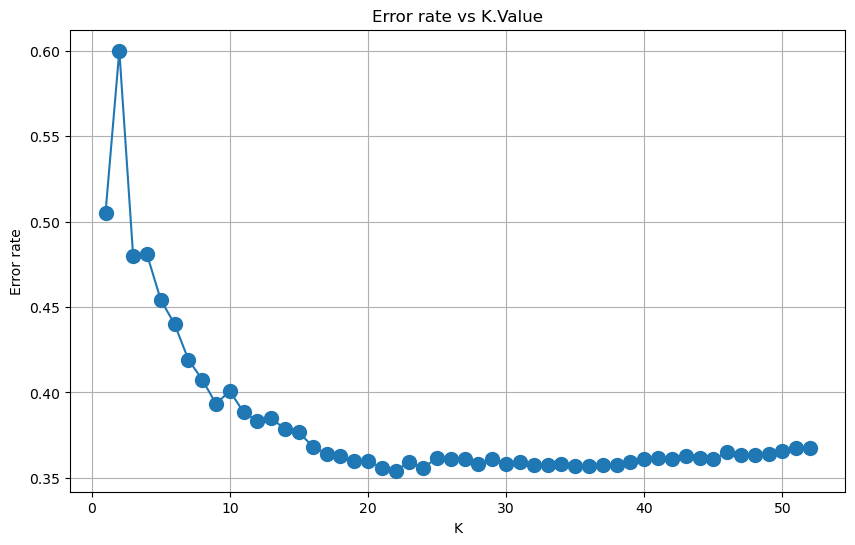

In [56]:
plt.figure(figsize=(10,6))
plt.plot(range(1, len(data.columns)+1), error_rate, marker='o', markersize=10)
plt.title('Error rate vs K.Value')
plt.xlabel('K')
plt.ylabel('Error rate')
plt.grid()

Найкращим значенням вийшло 22 сусіди

In [57]:
model_knn = KNeighborsClassifier(n_neighbors=22)
model_knn.fit(scaled_X_train, y_train.values.reshape(-1))
y_pred = model_knn.predict(scaled_X_test)

Точність, яка доля обʼєктів, яким модель присвоїла певний клас дійсно належить цьому обʼєкту:

$$Precision = TP / (TP + FP)$$

Повнота, яка доля обʼєктів із всіх реальних представників цього класа модель змогла правильно знайти та визначити (етака метрика відчутності):

$$Recall = TP / (TP + FN)$$

Баланс, F-метрика:

$$F1 = 2 * (Precision * Recall) / (Precision + Recall)$$

Точність на тестовій вибірці:

$$Accuracy = Всі~правильні~відповіді / к-ть~елементів$$

Макро-середнє:

$$Macro_{F1} = Сума~всіх~F1 / к-ть~класів$$

Взважене середнє:

$$Weight_{F1} = Сума~всіх (F1 * відповідний~support) / к-ть~елементів$$

In [58]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.59      0.08      0.15       226
           1       0.41      0.06      0.11       219
           2       0.65      0.98      0.79       755

    accuracy                           0.65      1200
   macro avg       0.55      0.38      0.35      1200
weighted avg       0.60      0.65      0.54      1200



Таблиця відображає відповідність між реальними класами та прогнозами моделі для трикласової класифікації. Рядки відповідають реальним класам, а стовпці — передбаченим моделлю. 

|                     | Передбачено Клас 0 | Передбачено Клас 1 | Передбачено Клас 2 |
| :------------------ | :----------------: | :----------------: | :----------------: |
| **Реальний Клас 0** |    **Правильно**   |     **Помилка**    |     **Помилка**    |
| **Реальний Клас 1** |     **Помилка**    |    **Правильно**   |     **Помилка**    |
| **Реальний Клас 2** |     **Помилка**    |     **Помилка**    |    **Правильно**   |


In [59]:
print(confusion_matrix(y_test,y_pred))

[[ 19  13 194]
 [  7  14 198]
 [  6   7 742]]


Підбраємо найкращі параметри за допомогою інструменту `GridSearchCV`.

- cv - к-ть прогонів;

- refit - після пошуку ще раз навчає модель на всіх даних з найкращими параметрами;

- $Macro_{F1} = Сума~всіх~F1 / к-ть~класів$

In [65]:
param_grid = {'n_neighbors' : range(1, len(data.columns)+1)}

In [72]:
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5,refit=True, scoring='f1_macro')

Тренуємо модель

In [73]:
grid.fit(scaled_X_train, y_train.values.reshape(-1))

,estimator,KNeighborsClassifier()
,param_grid,"{'n_neighbors': range(1, 53)}"
,scoring,'f1_macro'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,3


Найкращий результат сусідів

In [74]:
grid.best_params_

{'n_neighbors': 3}

Усі параметри моделі

In [75]:
grid.best_estimator_

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


Предиктимо

In [76]:
grid_predictions = grid.predict(scaled_X_test)

Точність, яка доля обʼєктів, яким модель присвоїла певний клас дійсно належить цьому обʼєкту:

$$Precision = TP / (TP + FP)$$

Повнота, яка доля обʼєктів із всіх реальних представників цього класа модель змогла правильно знайти та визначити (етака метрика відчутності):

$$Recall = TP / (TP + FN)$$

Баланс, F-метрика:

$$F1 = 2 * (Precision * Recall) / (Precision + Recall)$$

Точність на тестовій вибірці:

$$Accuracy = Всі~правильні~відповіді / к-ть~елементів$$

Макро-середнє:

$$Macro_{F1} = Сума~всіх~F1 / к-ть~класів$$

Взважене середнє:

$$Weight_{F1} = Сума~всіх (F1 * відповідний~support) / к-ть~елементів$$

In [77]:
print(classification_report(y_test,grid_predictions))

              precision    recall  f1-score   support

           0       0.25      0.28      0.27       226
           1       0.16      0.09      0.11       219
           2       0.66      0.72      0.69       755

    accuracy                           0.52      1200
   macro avg       0.35      0.36      0.35      1200
weighted avg       0.49      0.52      0.50      1200



Таблиця відображає відповідність між реальними класами та прогнозами моделі для трикласової класифікації. Рядки відповідають реальним класам, а стовпці — передбаченим моделлю. 

|                     | Передбачено Клас 0 | Передбачено Клас 1 | Передбачено Клас 2 |
| :------------------ | :----------------: | :----------------: | :----------------: |
| **Реальний Клас 0** |    **Правильно**   |     **Помилка**    |     **Помилка**    |
| **Реальний Клас 1** |     **Помилка**    |    **Правильно**   |     **Помилка**    |
| **Реальний Клас 2** |     **Помилка**    |     **Помилка**    |    **Правильно**   |


In [63]:
print(confusion_matrix(y_test,grid_predictions))

[[  6   8 212]
 [  4   3 212]
 [  2   1 752]]


In [64]:
print(accuracy_score(y_test,grid_predictions))

0.6341666666666667


#### SVC

Ядро - лінійне: $f(x) = \mathbf{w}^T \mathbf{x} + b$, де $\mathbf{w}$ - це вектор ваг ознак, $\mathbf{x}$ - це вектор вхідних ознак обʼєкта, b - біас.

С - це коефіцієнт регуляризації. 
- Чим більше C, тим менше регуляризації → модель намагається правильно класифікувати кожну точку (ризик перенавчання). 
- Чим менше C, тим більше регуляризації → спрощена межа, можливі помилки (краще узагальнення).

Гамма - коєфіцієнт ядра $1 / (n_features * X.var())$ (скейл за замовченням) - відстуній для лінійної моделі.

In [ ]:
model_SVC = SVC(C = 1.0, kernel='linear', class_weight='balanced', random_state=42)

Тренування

In [62]:
model_SVC.fit(scaled_X_train, y_train.values.reshape(-1))

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


Предиктимо

In [63]:
y_pred = model_SVC.predict(scaled_X_test)

Точність, яка доля обʼєктів, яким модель присвоїла певний клас дійсно належить цьому обʼєкту:

$$Precision = TP / (TP + FP)$$

Повнота, яка доля обʼєктів із всіх реальних представників цього класа модель змогла правильно знайти та визначити (етака метрика відчутності):

$$Recall = TP / (TP + FN)$$

Баланс, F-метрика:

$$F1 = 2 * (Precision * Recall) / (Precision + Recall)$$

Точність на тестовій вибірці:

$$Accuracy = Всі~правильні~відповіді / к-ть~елементів$$

Макро-середнє:

$$Macro_{F1} = Сума~всіх~F1 / к-ть~класів$$

Взважене середнє:

$$Weight_{F1} = Сума~всіх (F1 * відповідний~support) / к-ть~елементів$$

In [64]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.32      0.37      0.34       226
           1       0.27      0.28      0.28       219
           2       0.78      0.73      0.76       755

    accuracy                           0.58      1200
   macro avg       0.46      0.46      0.46      1200
weighted avg       0.60      0.58      0.59      1200



Таблиця відображає відповідність між реальними класами та прогнозами моделі для трикласової класифікації. Рядки відповідають реальним класам, а стовпці — передбаченим моделлю. 

|                     | Передбачено Клас 0 | Передбачено Клас 1 | Передбачено Клас 2 |
| :------------------ | :----------------: | :----------------: | :----------------: |
| **Реальний Клас 0** |    **Правильно**   |     **Помилка**    |     **Помилка**    |
| **Реальний Клас 1** |     **Помилка**    |    **Правильно**   |     **Помилка**    |
| **Реальний Клас 2** |     **Помилка**    |     **Помилка**    |    **Правильно**   |


In [65]:
print(confusion_matrix(y_test, y_pred))

[[ 84  68  74]
 [ 76  61  82]
 [106  95 554]]


Підбраємо найкращі параметри за допомогою інструменту `GridSearchCV`.

- cv - к-ть прогонів;

- refit - після пошуку ще раз навчає модель на всіх даних з найкращими параметрами;

- $Macro_{F1} = Сума~всіх~F1 / к-ть~класів$

Ядро - лінійне: $f(x) = \mathbf{w}^T \mathbf{x} + b$, де $\mathbf{w}$ - це вектор ваг ознак, $\mathbf{x}$ - це вектор вхідних ознак обʼєкта, b - біас.

Ядро - радіально-базисна функція: $K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma \cdot \Vert{}\mathbf{x} - \mathbf{x}'\Vert{}^2\right)$, де $\Vert{}\mathbf{x} - \mathbf{x}'\Vert{}^2$ - це квадрат евклідової відстані між двома обʼєктами, $\gamma$ - це радіус впливу одного опорного вектора (Маленьке gamma → широка межа (гладка, але може недонавчатись); Велике gamma → межа «підганяється» під точки (ризик переобучення)).

Ядро - поліноміальне: проводить межу у вигляді кривих ліній складної форми (параболи, гіперболи і т.д.), оцінюючи перетини ознак між собою. $K(\mathbf{x}, \mathbf{x}') = \left(\gamma \cdot \mathbf{x}^T \mathbf{x}' + c_0\right)^d$, де $\mathbf{x}^T \mathbf{x}'$ - це скалярний добуток векторів ознак двох об'єктів, $c_0$ - це вільний член, $d$ - степінь полінома, $\gamma$ - це коєфіцієнт скалярного добутка.

С - це коефіцієнт регуляризації. 
- Чим більше C, тим менше регуляризації → модель намагається правильно класифікувати кожну точку (ризик перенавчання). 
- Чим менше C, тим більше регуляризації → спрощена межа, можливі помилки (краще узагальнення).

Гамма - коєфіцієнт ядра $1 / (n_features * X.var())$ (скейл за замовченням)

In [78]:
param_grid = {'C': [0.005, 0.1, 0.7, 1, 10], 'gamma': [1,0.1,0.01,0.001,0.0001, 'scale', 'auto'], 'kernel': ['rbf', 'linear', 'poly'], 'class_weight':['balanced', None], 'random_state':[42]}

In [79]:
grid = GridSearchCV(SVC(), param_grid, cv=5,refit=True, scoring='f1_macro', n_jobs=-1)

Тренуємо

In [80]:
grid.fit(scaled_X_train, y_train.values.reshape(-1))

,estimator,SVC()
,param_grid,"{'C': [0.005, 0.1, ...], 'class_weight': ['balanced', None], 'gamma': [1, 0.1, ...], 'kernel': ['rbf', 'linear', ...], ...}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,0.7


Найкращі параметри

In [81]:
grid.best_params_

{'C': 0.7,
 'class_weight': 'balanced',
 'gamma': 1,
 'kernel': 'linear',
 'random_state': 42}

Усі параметри моделі

In [82]:
grid.best_estimator_

,C,0.7
,kernel,'linear'
,degree,3
,gamma,1
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


Предиктимо

In [83]:
grid_predictions = grid.predict(scaled_X_test)

Точність, яка доля обʼєктів, яким модель присвоїла певний клас дійсно належить цьому обʼєкту:

$$Precision = TP / (TP + FP)$$

Повнота, яка доля обʼєктів із всіх реальних представників цього класа модель змогла правильно знайти та визначити (етака метрика відчутності):

$$Recall = TP / (TP + FN)$$

Баланс, F-метрика:

$$F1 = 2 * (Precision * Recall) / (Precision + Recall)$$

Точність на тестовій вибірці:

$$Accuracy = Всі~правильні~відповіді / к-ть~елементів$$

Макро-середнє:

$$Macro_{F1} = Сума~всіх~F1 / к-ть~класів$$

Взважене середнє:

$$Weight_{F1} = Сума~всіх (F1 * відповідний~support) / к-ть~елементів$$

In [84]:
print(classification_report(y_test,grid_predictions))

              precision    recall  f1-score   support

           0       0.32      0.37      0.34       226
           1       0.27      0.28      0.28       219
           2       0.78      0.73      0.76       755

    accuracy                           0.58      1200
   macro avg       0.46      0.46      0.46      1200
weighted avg       0.60      0.58      0.59      1200



Таблиця відображає відповідність між реальними класами та прогнозами моделі для трикласової класифікації. Рядки відповідають реальним класам, а стовпці — передбаченим моделлю. 

|                     | Передбачено Клас 0 | Передбачено Клас 1 | Передбачено Клас 2 |
| :------------------ | :----------------: | :----------------: | :----------------: |
| **Реальний Клас 0** |    **Правильно**   |     **Помилка**    |     **Помилка**    |
| **Реальний Клас 1** |     **Помилка**    |    **Правильно**   |     **Помилка**    |
| **Реальний Клас 2** |     **Помилка**    |     **Помилка**    |    **Правильно**   |


In [85]:
print(confusion_matrix(y_test,grid_predictions))

[[ 84  68  74]
 [ 76  61  82]
 [106  95 554]]


#### Порівняння моделей класифікації

**Загальна таблиця метрик (Accuracy, Macro F1, Weighted F1)**

| Модель | Accuracy | Macro Precision | Macro Recall | Macro F1 | Weighted F1 |
|---|---|---|---|---|---|
| **Decision Tree** | 0.57 | 0.45 | 0.45 | 0.45 | 0.58 |
| **Random Forest** | 0.64 | 0.46 | 0.38 | 0.36 | 0.55 |
| **AdaBoost** | **0.65** | 0.50 | 0.37 | 0.33 | 0.53 |
| **KNC** | 0.60 | 0.39 | 0.36 | 0.35 | 0.53 |
| **KNC (optimized Train)** | **0.65** | **0.55** | 0.38 | 0.35 | 0.54 |
| **KNN (GridSearchCV)** | 0.52 | 0.35 | 0.36 | 0.35 | 0.50 |
| **SVC** | 0.58 | 0.46 | 0.46 | 0.46 | **0.59** |
| **SVC (GridSearch)** | 0.58 | 0.46 | 0.46 | **0.46** | **0.59** |

---

**Confusion Matrix**

| Модель | Confusion Matrix |
|--------|------------------|
| **Random Forest** | `[[25, 23, 178], [20, 17, 182], [20, 14, 721]]` |
| **AdaBoost** | `[[22, 9, 195], [15, 5, 199], [7, 1, 747]]` |
| **KNC** | `[[28, 23, 175], [22, 16, 181], [38, 42, 675]]` |
| **KNC (optimized Train)** | `[[19, 13, 194], [7, 14, 198], [6, 7, 742]]` |
| **KNN (GridSearchCV)** | `[[6, 8, 212], [4, 3, 212], [2, 1, 752]]` |
| **SVC** | `[[84, 68, 74], [76, 61, 82], [106, 95, 554]]` |
| **SVC (GridSearch)** | `[[84, 68, 74], [76, 61, 82], [106, 95, 554]]` |

---

За точністю найкращими є AdaBoost та KNC (optimized Train), проте вони дуже погано визначають 0 і 1 класи та отримують високу точність в основному завдяки великій кількості об'єктів класу 2.

Однак, якщо брати загальний результат, то для цього датасета найкращою моделлю за комплексними метриками є SVC. Вона краще розпізнає всі класи та має найкращий показник Macro F1. При цьому більшість інших моделей мають більшу схильність до мажоритарного класу 2.
